# AI-Optimized Trim & Fuse: MCU predictive trim model

**Goal:** predict each MCU die's best **trim code** from data the tester already has, so the tester can apply the code, verify it with one measurement, and skip the slow binary-search loop (6 to 8 iterations per trim).

**Dataset:** `mcu_trim_fuse.csv` (8,420 dies, 3 derivatives: MCU-A, MCU-B, MCU-C)

**Targets (what we predict):**

| Target | What it is | Range |
|---|---|---|
| `bg_trim_code_opt` | Bandgap trim code (**main target**) | 0 to 63 (6-bit) |
| `hsi_trim_code_opt` | 16 MHz oscillator trim code (hardest) | 0 to 127 (7-bit) |
| `ldo_trim_code_opt` | LDO regulator trim code | 0 to 31 (5-bit) |

**Notebook flow:**
1. Load the data and understand every column
2. EDA (exploratory data analysis)
3. Group the data by wafer and split it into train and test
4. Formula baseline, then 6 ML models, compared side by side
5. Evaluation with ML metrics and domain (test-floor) metrics
6. Optimization check: feature engineering and hyperparameter tuning
7. Final model selection and saving
8. Drift-aware bandgap target for MCU-C (packaging drift)
9. Can deep learning, GANs or reinforcement learning help?
10. Why this project and why this model

**How to run in Google Colab:** upload this notebook, then run the cells top to bottom (Runtime → Run all). The load cell asks you to upload `mcu_trim_fuse.csv` if it is not found.

## 0. Setup
Import the libraries. `xgboost` and `lightgbm` are preinstalled in Colab; the `pip` line only runs if they are missing.

In [1]:
import importlib, subprocess, sys
for pkg in ["xgboost", "lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
print("Libraries loaded")

Libraries loaded


# Part 1: Load the data and understand the columns

## 1.1 Load the CSV
Looks for `mcu_trim_fuse.csv` next to the notebook. In Colab, if it is missing, a file-upload box appears.

In [2]:
CSV = "mcu_trim_fuse.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files
        print("Please upload mcu_trim_fuse.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put mcu_trim_fuse.csv in the same folder as this notebook")

df = pd.read_csv(CSV)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 8420 | Columns: 42


,die_id,lot_id,wafer_id,derivative,die_x,die_y,x_mm,y_mm,radius_mm,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,package,temp_grade,latent_defect,bg_untrim_V,bg_trim_code_opt,bg_trimmed_sort_V,bg_conv_iterations,hsi_untrim_MHz,hsi_trim_code_opt,hsi_trimmed_sort_MHz,hsi_conv_iterations,ldo_untrim_V,ldo_trim_code_opt,ldo_trimmed_sort_V,ldo_conv_iterations,ts_cal1_30C_counts,ts_slope_counts_per_C_true,ts_cal2_110C_counts,ts_cal2_measured_on_tester,sram_fail_bits,sram_repairable,conv_trim_time_ms,sort_pass,bg_final_V,hsi_final_MHz,ldo_final_V,final_pass,fuse_map_hex
0,MCU-000000,MA1,MA1-W01,MCU-A,9,1,-24.0,-88.0,91.21,452.04,-477.49,284.88,20.435,1.0356,QFN48,industrial,False,1.19017,37,1.20051,6,16.98648,36,16.04461,7,1.09439,17,1.09872,7,1055,3.2525,1316,False,0,True,28.2,True,1.20278,15.99442,1.10050,True,0x000002FF507E2925
1,MCU-000001,MA1,MA1-W01,MCU-A,10,1,-16.0,-88.0,89.44,434.45,-489.77,283.29,20.743,1.0051,QFN48,industrial,False,1.17902,43,1.20058,6,17.09167,34,15.99064,9,1.08332,20,1.10155,5,1036,3.2709,1299,False,0,True,30.2,True,1.20148,15.97626,1.10505,True,0x000002FF503288AB
2,MCU-000002,MA1,MA1-W01,MCU-A,11,1,-8.0,-88.0,88.36,440.99,-478.68,278.32,20.573,1.0356,QFN48,industrial,False,1.18039,42,1.20093,6,16.91557,36,15.99795,7,1.09265,17,1.09795,5,1037,3.2503,1295,False,1,True,26.2,True,1.20278,15.94578,1.09791,True,0x000002FF5036292A
3,MCU-000003,MA1,MA1-W01,MCU-A,12,1,0.0,-88.0,88.00,443.30,-478.89,276.77,20.692,1.0364,QFN48,industrial,False,1.18716,38,1.19928,8,17.15366,34,16.00976,7,1.09164,18,1.10045,5,1034,3.3032,1299,False,1,True,28.6,True,1.19943,16.00254,1.10395,True,0x000002FF502A48A6
4,MCU-000004,MA1,MA1-W01,MCU-A,13,1,8.0,-88.0,88.36,444.34,-493.97,275.77,20.914,1.0753,QFN48,industrial,False,1.17894,42,1.20004,6,17.31154,28,15.99240,7,1.08942,18,1.09873,6,1044,3.3334,1309,False,0,True,27.2,True,1.20162,15.98817,1.10252,True,0x000002FF5052472A


## 1.2 Column types
`info()` shows each column's data type and how many non-empty values it has.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8420 entries, 0 to 8419
Data columns (total 42 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   die_id                      8420 non-null   str    
 1   lot_id                      8420 non-null   str    
 2   wafer_id                    8420 non-null   str    
 3   derivative                  8420 non-null   str    
 4   die_x                       8420 non-null   int64  
 5   die_y                       8420 non-null   int64  
 6   x_mm                        8420 non-null   float64
 7   y_mm                        8420 non-null   float64
 8   radius_mm                   8420 non-null   float64
 9   pcm_vth_n_mV                8420 non-null   float64
 10  pcm_vth_p_mV                8420 non-null   float64
 11  pcm_rs_ohm_sq               8420 non-null   float64
 12  pcm_tox_A                   8420 non-null   float64
 13  pcm_mobility_rel            8420 non-null   

## 1.3 What every column means, and its role
Each column has a **role**:
- **id**: just a key, never used for modelling
- **group**: used to split the data (wafer), not as a feature
- **feature**: known on the tester *before* trimming, so the model may use it
- **target**: the answer we predict
- **leak**: only known *after* trimming or packaging. Using it as a feature would be cheating (data leakage)
- **info**: context and cost columns used for savings calculations

In [4]:
col_info = {
    "die_id": ("id", "Unique die identifier"),
    "lot_id": ("group", "Fab lot"),
    "wafer_id": ("group", "Wafer; split train/test by this"),
    "derivative": ("info", "Product variant: MCU-A / MCU-B / MCU-C"),
    "die_x": ("feature", "Die column index on the wafer"),
    "die_y": ("feature", "Die row index on the wafer"),
    "x_mm": ("feature", "Die x position from wafer centre (mm)"),
    "y_mm": ("feature", "Die y position from wafer centre (mm)"),
    "radius_mm": ("feature", "Distance from wafer centre (mm)"),
    "pcm_vth_n_mV": ("feature", "Process monitor: NMOS threshold voltage"),
    "pcm_vth_p_mV": ("feature", "Process monitor: PMOS threshold voltage"),
    "pcm_rs_ohm_sq": ("feature", "Process monitor: poly sheet resistance"),
    "pcm_tox_A": ("feature", "Process monitor: gate oxide thickness"),
    "pcm_mobility_rel": ("feature", "Process monitor: carrier mobility"),
    "package": ("info", "Package type (drives drift after packaging)"),
    "temp_grade": ("info", "Industrial or automotive"),
    "latent_defect": ("target", "Hidden defect (for anomaly screening)"),
    "bg_untrim_V": ("feature", "Bandgap before trim (target 1.200 V)"),
    "bg_trim_code_opt": ("target", "Best bandgap trim code, 0-63 (MAIN TARGET)"),
    "bg_trimmed_sort_V": ("leak", "Bandgap after trim at sort"),
    "bg_conv_iterations": ("info", "Binary-search steps used today for bandgap"),
    "hsi_untrim_MHz": ("feature", "Oscillator before trim (target 16 MHz)"),
    "hsi_trim_code_opt": ("target", "Best oscillator trim code, 0-127"),
    "hsi_trimmed_sort_MHz": ("leak", "Oscillator after trim at sort"),
    "hsi_conv_iterations": ("info", "Binary-search steps used today for HSI"),
    "ldo_untrim_V": ("feature", "LDO before trim (target 1.10 V)"),
    "ldo_trim_code_opt": ("target", "Best LDO trim code, 0-31"),
    "ldo_trimmed_sort_V": ("leak", "LDO after trim at sort"),
    "ldo_conv_iterations": ("info", "Binary-search steps used today for LDO"),
    "ts_cal1_30C_counts": ("feature", "Temperature sensor reading at 30 C"),
    "ts_slope_counts_per_C_true": ("target", "True temperature-sensor slope"),
    "ts_cal2_110C_counts": ("target", "Temperature sensor reading at 110 C"),
    "ts_cal2_measured_on_tester": ("info", "True only for MCU-C"),
    "sram_fail_bits": ("feature", "Failing SRAM bits at sort"),
    "sram_repairable": ("target", "SRAM repairable with 2 spare rows"),
    "conv_trim_time_ms": ("info", "Trim test time today (ms per die)"),
    "sort_pass": ("leak", "Passed wafer sort"),
    "bg_final_V": ("leak", "Bandgap after packaging (spec 1.200 V +/- 5 mV)"),
    "hsi_final_MHz": ("leak", "Oscillator after packaging"),
    "ldo_final_V": ("leak", "LDO after packaging"),
    "final_pass": ("leak", "Passed final test after packaging"),
    "fuse_map_hex": ("leak", "64-bit fuse word (contains the trim codes)"),
}
cols = pd.DataFrame(
    [(c, *col_info[c], str(df[c].dtype), df[c].nunique(), df[c].iloc[0]) for c in df.columns],
    columns=["column", "role", "meaning", "dtype", "unique_values", "example"])
print(cols.role.value_counts().to_string())
cols

role
feature    15
leak        9
info        8
target      7
group       2
id          1


,column,role,meaning,dtype,unique_values,example
0,die_id,id,Unique die identifier,str,8420,MCU-000000
1,lot_id,group,Fab lot,str,5,MA1
2,wafer_id,group,Wafer; split train/test by this,str,20,MA1-W01
3,derivative,info,Product variant: MCU-A / MCU-B / MCU-C,str,3,MCU-A
4,die_x,feature,Die column index on the wafer,int64,23,9
5,die_y,feature,Die row index on the wafer,int64,23,1
6,x_mm,feature,Die x position from wafer centre (mm),float64,23,-24.0
7,y_mm,feature,Die y position from wafer centre (mm),float64,23,-88.0
8,radius_mm,feature,Distance from wafer centre (mm),float64,56,91.21
9,pcm_vth_n_mV,feature,Process monitor: NMOS threshold voltage,float64,3852,452.04


## 1.4 Data quality: missing values and duplicates
Clean data needs no imputation. This checks it.

In [5]:
print("Missing values in total :", int(df.isna().sum().sum()))
print("Duplicate rows          :", int(df.duplicated().sum()))
print("Duplicate die_id        :", int(df.die_id.duplicated().sum()))

Missing values in total : 0
Duplicate rows          : 0
Duplicate die_id        : 0


## 1.5 Summary statistics of the numeric columns

In [6]:
df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
die_x,8420.0,12.0000,5.7867,1.0000,7.0000,12.0000,17.0000,23.0000
die_y,8420.0,12.0000,5.7867,1.0000,7.0000,12.0000,17.0000,23.0000
x_mm,8420.0,0.0000,46.2938,-88.0000,-40.0000,0.0000,40.0000,88.0000
y_mm,8420.0,0.0000,46.2938,-88.0000,-40.0000,0.0000,40.0000,88.0000
radius_mm,8420.0,61.7211,21.8217,0.0000,46.6500,64.5000,80.0000,91.2100
pcm_vth_n_mV,8420.0,442.6939,11.7875,394.9100,435.2750,442.8400,450.6300,477.8200
pcm_vth_p_mV,8420.0,-485.5052,13.2130,-525.6100,-494.3200,-483.8300,-476.1275,-452.8000
pcm_rs_ohm_sq,8420.0,295.6769,14.1918,258.5900,283.0500,298.1100,307.8300,330.0100
pcm_tox_A,8420.0,20.1757,0.4215,18.7620,19.9470,20.2180,20.4830,21.2480
pcm_mobility_rel,8420.0,0.9986,0.0447,0.8619,0.9684,0.9953,1.0267,1.1515


## 1.6 How the data is grouped: derivatives, lots and wafers
MCU-A is the big base product. MCU-B and MCU-C have much less data, which is why the project brief talks about **transfer learning**.

In [7]:
summary = df.groupby("derivative").agg(
    dies=("die_id", "count"), lots=("lot_id", "nunique"), wafers=("wafer_id", "nunique"),
    package=("package", "first"), grade=("temp_grade", "first"))
print(summary.to_string())
print("\nDies per wafer (min / mean / max):",
      df.groupby("wafer_id").size().agg(["min", "mean", "max"]).round(0).to_dict())

            dies  lots  wafers  package       grade
derivative                                         
MCU-A       6315     3      15    QFN48  industrial
MCU-B       1263     1       3    QFN32  industrial
MCU-C        842     1       2  LQFP100  automotive

Dies per wafer (min / mean / max): {'min': 421.0, 'mean': 421.0, 'max': 421.0}


## 1.7 The three targets at a glance
The middle code (32, 64, 16) means "no change". Codes far from the middle mean the die was far off target before trimming.

In [8]:
for t, bits in [("bg_trim_code_opt", 6), ("hsi_trim_code_opt", 7), ("ldo_trim_code_opt", 5)]:
    s = df[t]
    print(f"{t:20s} allowed 0-{2**bits-1:3d} | used {s.min():3d}-{s.max():3d} | "
          f"mean {s.mean():6.2f} | unique codes {s.nunique()}")

bg_trim_code_opt     allowed 0- 63 | used   0- 63 | mean  35.59 | unique codes 49
hsi_trim_code_opt    allowed 0-127 | used   6-125 | mean  59.17 | unique codes 114
ldo_trim_code_opt    allowed 0- 31 | used   9- 29 | mean  17.59 | unique codes 21


# Part 2: EDA (exploratory data analysis)

## 2.1 Untrimmed readings vs. their targets
How far each circuit is from its target before trimming. The wider the spread, the more trimming is needed.

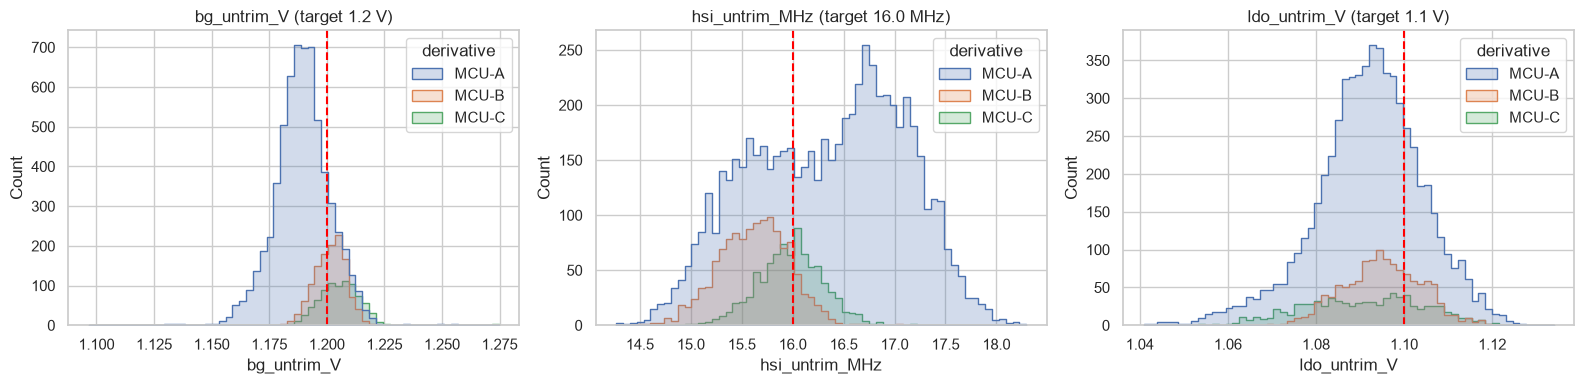

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (col, tgt, unit) in zip(ax, [("bg_untrim_V", 1.200, "V"), ("hsi_untrim_MHz", 16.0, "MHz"),
                                     ("ldo_untrim_V", 1.10, "V")]):
    sns.histplot(data=df, x=col, hue="derivative", bins=60, ax=a, element="step")
    a.axvline(tgt, color="red", ls="--", label="target")
    a.set_title(f"{col} (target {tgt} {unit})")
plt.tight_layout(); plt.show()

## 2.2 Distribution of the trim codes
These are the targets. All three are bell-shaped around the "no change" code.

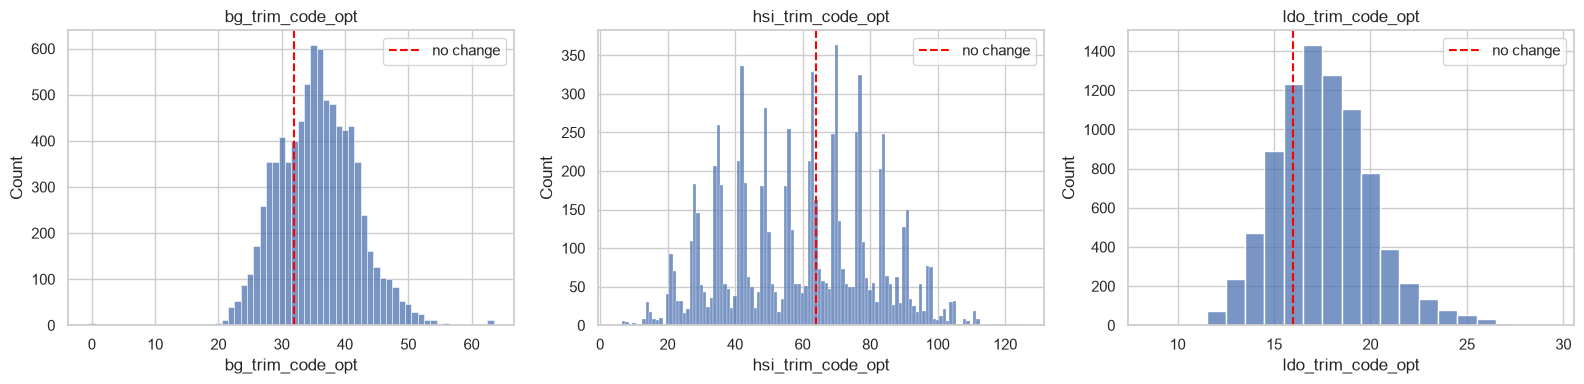

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (col, mid) in zip(ax, [("bg_trim_code_opt", 32), ("hsi_trim_code_opt", 64), ("ldo_trim_code_opt", 16)]):
    sns.histplot(df[col], discrete=True, ax=a)
    a.axvline(mid, color="red", ls="--", label="no change")
    a.set_title(col); a.legend()
plt.tight_layout(); plt.show()

## 2.3 Untrimmed reading vs. trim code (the key relationship)
If this is close to a straight line, a simple formula already gets close. The **spread around the line** is what ML must learn: each die's trim DAC has its own gain error and non-linearity.

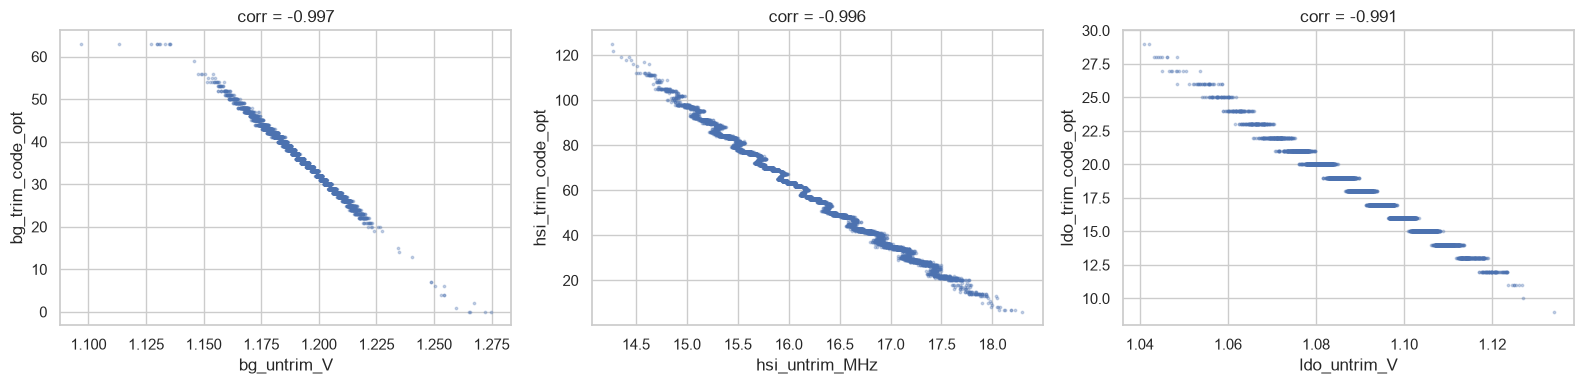

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (x, y) in zip(ax, [("bg_untrim_V", "bg_trim_code_opt"), ("hsi_untrim_MHz", "hsi_trim_code_opt"),
                          ("ldo_untrim_V", "ldo_trim_code_opt")]):
    a.scatter(df[x], df[y], s=3, alpha=0.3)
    a.set_xlabel(x); a.set_ylabel(y)
    a.set_title(f"corr = {df[x].corr(df[y]):.3f}")
plt.tight_layout(); plt.show()

## 2.4 Correlation heatmap
Which features move together with the targets. Values near +1 or -1 are strong.

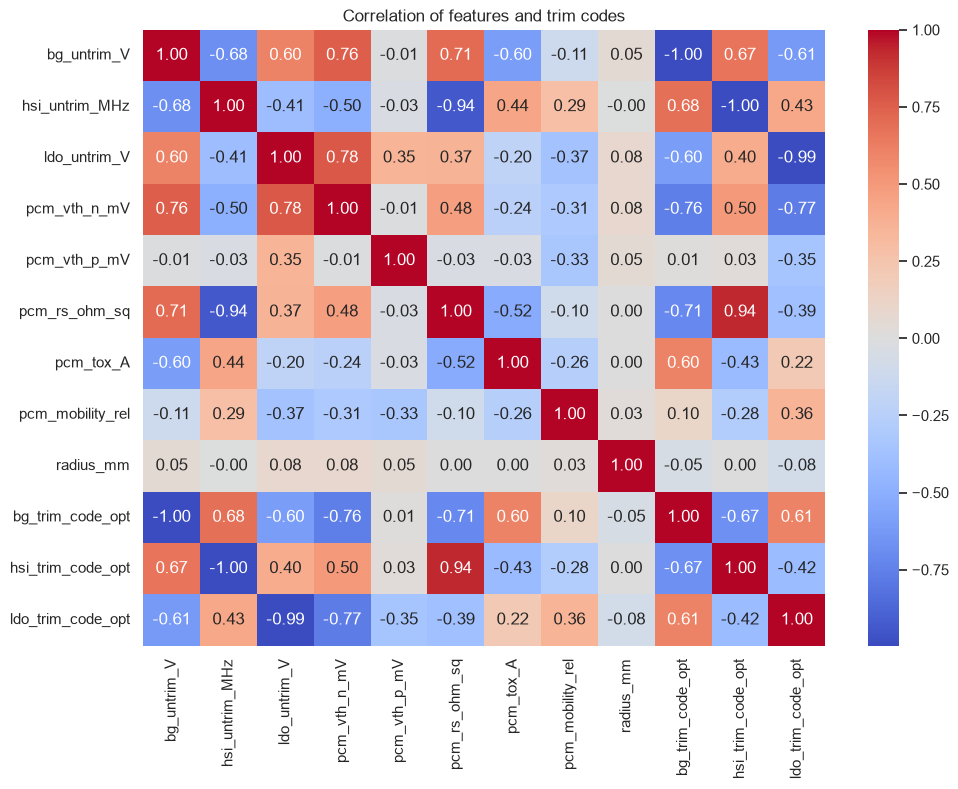

In [12]:
corr_cols = ["bg_untrim_V", "hsi_untrim_MHz", "ldo_untrim_V", "pcm_vth_n_mV", "pcm_vth_p_mV",
             "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel", "radius_mm",
             "bg_trim_code_opt", "hsi_trim_code_opt", "ldo_trim_code_opt"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of features and trim codes"); plt.show()

## 2.5 Wafer maps
Each dot is a die at its real position on the wafer. Patterns (rings, tilt) prove that **position matters**, so `x_mm`, `y_mm` and `radius_mm` are useful features.

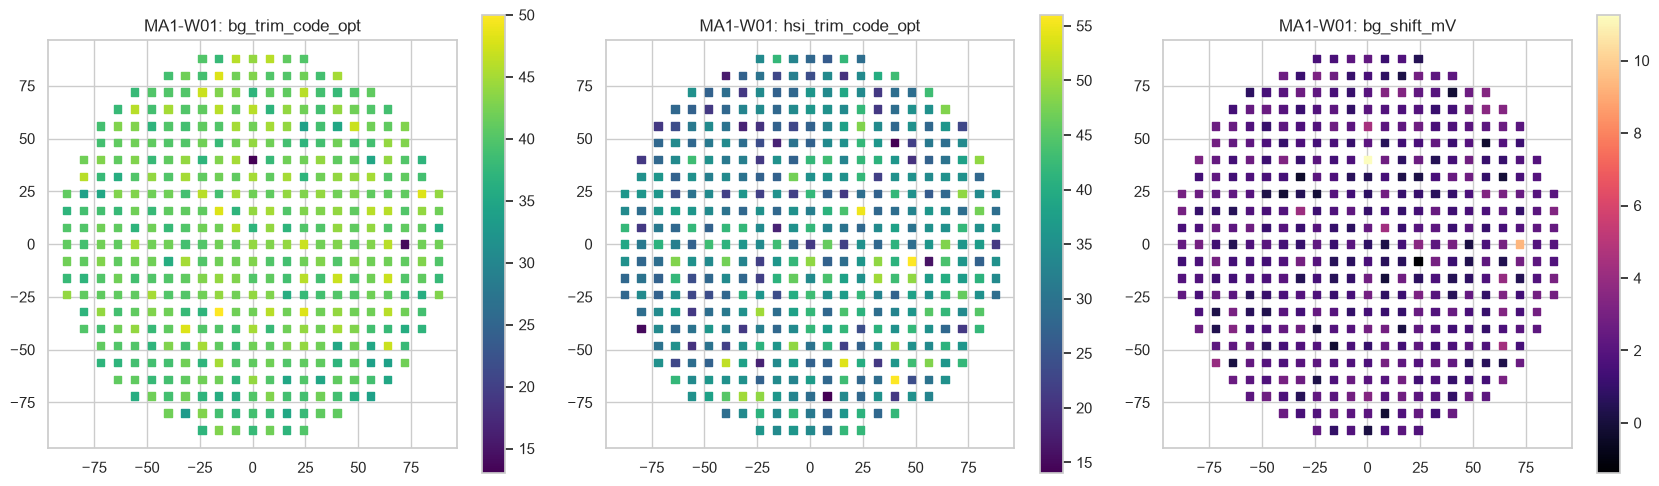

In [13]:
w = df[df.derivative == "MCU-A"].wafer_id.iloc[0]
one = df[df.wafer_id == w].copy()
one["bg_shift_mV"] = (one.bg_final_V - one.bg_trimmed_sort_V) * 1000
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, (col, cmap) in zip(ax, [("bg_trim_code_opt", "viridis"), ("hsi_trim_code_opt", "viridis"),
                               ("bg_shift_mV", "magma")]):
    sc = a.scatter(one.x_mm, one.y_mm, c=one[col], cmap=cmap, s=28, marker="s")
    plt.colorbar(sc, ax=a); a.set_title(f"{w}: {col}"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

## 2.6 Drift after packaging (sort → final test)
After the die is packaged, the bandgap shifts. MCU-C (LQFP100, automotive) shifts the most, and the shift grows toward the wafer edge. This is the "drift-aware target" idea in the brief.

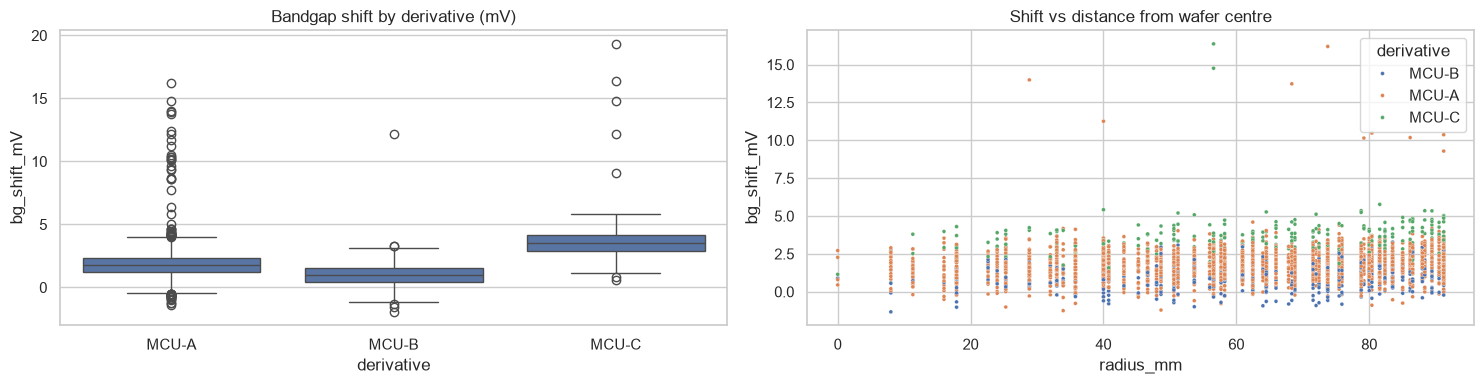

            mean   std
derivative            
MCU-A       1.80  1.02
MCU-B       0.98  0.88
MCU-C       3.59  1.24


In [14]:
df["bg_shift_mV"] = (df.bg_final_V - df.bg_trimmed_sort_V) * 1000
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=df, x="derivative", y="bg_shift_mV", ax=ax[0]); ax[0].set_title("Bandgap shift by derivative (mV)")
sns.scatterplot(data=df.sample(3000, random_state=SEED), x="radius_mm", y="bg_shift_mV",
                hue="derivative", s=8, ax=ax[1]); ax[1].set_title("Shift vs distance from wafer centre")
plt.tight_layout(); plt.show()
print(df.groupby("derivative").bg_shift_mV.agg(["mean", "std"]).round(2).to_string())

## 2.7 Pass rates and defects by derivative
Fail rates are small (an imbalanced problem), which matters if we later classify pass/fail.

In [15]:
rates = df.groupby("derivative")[["sort_pass", "final_pass", "latent_defect", "sram_repairable"]].mean() * 100
print(rates.round(2).to_string())

            sort_pass  final_pass  latent_defect  sram_repairable
derivative                                                       
MCU-A           99.56       99.27           0.38            99.71
MCU-B           99.76       99.76           0.08            99.84
MCU-C           99.64       90.62           0.59            99.76


## 2.8 What trimming costs today
Today each trim uses a binary search: one measurement per bit plus retries. A simple regression of test time on iterations recovers the **milliseconds per iteration** for each trim; we use these numbers later to calculate the time AI saves.

In [16]:
it_cols = ["bg_conv_iterations", "hsi_conv_iterations", "ldo_conv_iterations"]
print(df[it_cols + ["conv_trim_time_ms"]].describe().loc[["mean", "min", "max"]].round(2).to_string())
coef, *_ = np.linalg.lstsq(df[it_cols].values, df.conv_trim_time_ms.values, rcond=None)
MS_PER_ITER = dict(zip(["bg", "hsi", "ldo"], coef.round(2)))
print("\nms per iteration:", MS_PER_ITER)

      bg_conv_iterations  hsi_conv_iterations  ldo_conv_iterations  conv_trim_time_ms
mean                6.59                 7.59                  5.6              28.67
min                 6.00                 7.00                  5.0              26.20
max                 8.00                 9.00                  7.0              34.60

ms per iteration: {'bg': np.float64(1.2), 'hsi': np.float64(2.0), 'ldo': np.float64(1.0)}


## 2.9 Outlier check (IQR rule)
Counts values outside 1.5 × IQR. We keep the outliers: in test data they are real dies (often latent defects), and removing them would hide exactly the cases the tester must handle.

In [17]:
num = ["bg_untrim_V", "hsi_untrim_MHz", "ldo_untrim_V", "pcm_vth_n_mV", "pcm_vth_p_mV",
       "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
out = ((df[num] < q1 - 1.5 * (q3 - q1)) | (df[num] > q3 + 1.5 * (q3 - q1)))
print(pd.DataFrame({"outliers": out.sum(), "pct": (out.mean() * 100).round(2)}).to_string())
print("\nOutlier dies that are latent defects:", int(df[out.any(axis=1)].latent_defect.sum()),
      "of", int(df.latent_defect.sum()))

                  outliers   pct
bg_untrim_V             78  0.93
hsi_untrim_MHz           0  0.00
ldo_untrim_V           184  2.19
pcm_vth_n_mV           126  1.50
pcm_vth_p_mV            11  0.13
pcm_rs_ohm_sq            0  0.00
pcm_tox_A              154  1.83
pcm_mobility_rel       112  1.33

Outlier dies that are latent defects: 30 of 30


## 2.10 EDA summary
- The data is clean: no missing values and no duplicates.
- The untrimmed reading is the strongest single predictor of each trim code (near-linear).
- Process monitors (PCM) and wafer position add information: the wafer maps show radial and tilt patterns.
- MCU-A has most of the data. MCU-B and MCU-C are small, so a model trained on MCU-A should be checked on them.
- Packaging drift depends on package and radius, and is largest for MCU-C.
- Today's trim costs about 7 iterations per trim (about 29 ms per die for all three trims).

# Part 3: Group by wafer and split

## 3.1 Why split by wafer?
Dies on the same wafer are very similar (same process conditions). With a random split, the test set contains "neighbours" of training dies and the score looks better than it will be on a **new wafer**. So whole wafers go to either train or test, never both.

We train on **MCU-A** (the base product) and keep **MCU-B and MCU-C** apart to test how well the model transfers to derivatives.

In [18]:
base = df[df.derivative == "MCU-A"].reset_index(drop=True)
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
tr_idx, te_idx = next(gss.split(base, groups=base.wafer_id))
train, test = base.iloc[tr_idx].reset_index(drop=True), base.iloc[te_idx].reset_index(drop=True)
others = df[df.derivative != "MCU-A"].reset_index(drop=True)

print("Train:", len(train), "dies from", train.wafer_id.nunique(), "wafers")
print("Test :", len(test), "dies from", test.wafer_id.nunique(), "wafers ->", sorted(test.wafer_id.unique()))
print("Shared wafers between train and test:", len(set(train.wafer_id) & set(test.wafer_id)))
print("MCU-B / MCU-C transfer set:", others.derivative.value_counts().to_dict())

Train: 4631 dies from 11 wafers
Test : 1684 dies from 4 wafers -> ['MA1-W01', 'MA2-W05', 'MA3-W02', 'MA3-W04']
Shared wafers between train and test: 0
MCU-B / MCU-C transfer set: {'MCU-B': 1263, 'MCU-C': 842}


## 3.2 Settings for each trim and the feature lists
- `T` holds each trim's physics: bits, "no change" code, target, step size per code (LSB), and the sort spec.
- **BASE features** = the untrimmed reading + 5 process monitors + wafer position. These are all known before trimming.
- The **leak** columns from 1.3 are never used.

In [19]:
T = {
    "bg":  dict(label="bg_trim_code_opt",  untrim="bg_untrim_V",    bits=6, mid=32, target=1.200, lsb=0.002,
                mult=False, trimmed="bg_trimmed_sort_V",    spec=0.004, conv="bg_conv_iterations"),
    "hsi": dict(label="hsi_trim_code_opt", untrim="hsi_untrim_MHz", bits=7, mid=64, target=16.0,  lsb=0.002,
                mult=True,  trimmed="hsi_trimmed_sort_MHz", spec=0.005, conv="hsi_conv_iterations"),
    "ldo": dict(label="ldo_trim_code_opt", untrim="ldo_untrim_V",   bits=5, mid=16, target=1.10,  lsb=0.005,
                mult=False, trimmed="ldo_trimmed_sort_V",   spec=0.011, conv="ldo_conv_iterations"),
}
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
BASE_FEATS = {t: [T[t]["untrim"]] + PCM + POS for t in T}
LEAK = cols[cols.role == "leak"].column.tolist()
assert not any(f in LEAK for fs in BASE_FEATS.values() for f in fs), "leakage!"
for t, f in BASE_FEATS.items():
    print(t, "->", f)

bg -> ['bg_untrim_V', 'pcm_vth_n_mV', 'pcm_vth_p_mV', 'pcm_rs_ohm_sq', 'pcm_tox_A', 'pcm_mobility_rel', 'x_mm', 'y_mm', 'radius_mm']
hsi -> ['hsi_untrim_MHz', 'pcm_vth_n_mV', 'pcm_vth_p_mV', 'pcm_rs_ohm_sq', 'pcm_tox_A', 'pcm_mobility_rel', 'x_mm', 'y_mm', 'radius_mm']
ldo -> ['ldo_untrim_V', 'pcm_vth_n_mV', 'pcm_vth_p_mV', 'pcm_rs_ohm_sq', 'pcm_tox_A', 'pcm_mobility_rel', 'x_mm', 'y_mm', 'radius_mm']


# Part 4: Formula baseline, ML models and comparison

## 4.1 Evaluation function (ML metrics + domain metrics)
A trim code is a whole number, so the prediction is **rounded and clipped** to the allowed range.

| Metric | Meaning | Better |
|---|---|---|
| MAE / RMSE | Average error in code steps | lower |
| R² | Share of variation explained | higher |
| **Exact %** | Predicted code is exactly the best code | higher |
| **±1 code %** | Within one step (the tester fixes this with 1 extra measurement) | higher |
| ±2 code % | Within two steps | higher |
| **AI iterations** | Predict → verify: 1 if exact, 2 if off by 1, otherwise fall back to the full search (1 + bits) | lower |
| **Iterations saved %** | vs. today's binary search | higher |
| **Spec pass %** | Trimmed value still inside the sort spec with the predicted code (approximation using the ideal step size) | higher |
| Edge-code % | Predicted code at 0 or max; flagged for the conventional fallback and anomaly review | lower |

In [20]:
def to_code(pred, t):
    return np.clip(np.round(pred), 0, 2 ** T[t]["bits"] - 1).astype(int)

def evaluate(t, data, pred_raw, name=""):
    c = T[t]; y = data[c["label"]].values
    code_ = to_code(pred_raw, t); err = np.abs(code_ - y)
    ai_iters = np.where(err == 0, 1, np.where(err <= 1, 2, 1 + c["bits"]))
    conv = data[c["conv"]].values
    # value the die would have with the predicted code (ideal step size)
    if c["mult"]:
        val = data[c["trimmed"]].values * (1 + (code_ - y) * c["lsb"])
        ok = np.abs(val / c["target"] - 1) <= c["spec"]
    else:
        val = data[c["trimmed"]].values + (code_ - y) * c["lsb"]
        ok = np.abs(val - c["target"]) <= c["spec"]
    return {"model": name, "trim": t,
            "MAE": mean_absolute_error(y, pred_raw), "RMSE": mean_squared_error(y, pred_raw) ** 0.5,
            "R2": r2_score(y, pred_raw), "exact_%": (err == 0).mean() * 100,
            "within1_%": (err <= 1).mean() * 100, "within2_%": (err <= 2).mean() * 100,
            "AI_iters": ai_iters.mean(), "conv_iters": conv.mean(),
            "iters_saved_%": (1 - ai_iters.mean() / conv.mean()) * 100,
            "spec_pass_%": ok.mean() * 100,
            "edge_code_%": np.isin(code_, [0, 2 ** c["bits"] - 1]).mean() * 100}
print("Evaluation function ready")

Evaluation function ready


## 4.2 Formula baseline (no ML)
Physics only: code = no-change code − (error from target) ÷ (step size). It assumes every die's trim DAC is perfect. Any ML model must beat this to be worth using.

In [21]:
def formula_code(t, data):
    c = T[t]; u = data[c["untrim"]].values
    if c["mult"]:
        return c["mid"] + (c["target"] / u - 1) / c["lsb"]
    return c["mid"] - (u - c["target"]) / c["lsb"]

results = [evaluate(t, test, formula_code(t, test), "Formula baseline") for t in T]
pd.DataFrame(results).round(3)

,model,trim,MAE,RMSE,R2,exact_%,within1_%,within2_%,AI_iters,conv_iters,iters_saved_%,spec_pass_%,edge_code_%
0,Formula baseline,bg,0.345,0.543,0.989,78.325,99.644,100.000,1.235,6.601,81.297,99.762,0.297
1,Formula baseline,hsi,1.150,1.395,0.996,23.990,69.359,94.121,3.599,7.606,52.686,92.993,0.000
2,Formula baseline,ldo,0.285,0.340,0.971,86.105,100.000,100.000,1.139,5.596,79.646,100.000,0.000


## 4.3 The candidate models
Six different model families, so we can see which works best:

| Model | Type | Why try it |
|---|---|---|
| Ridge | Linear | Simple, explainable reference |
| Random Forest | Tree ensemble (bagging) | Robust, little tuning |
| HistGradientBoosting | Tree boosting | Used by the dataset's reference baseline |
| XGBoost | Tree boosting | Industry-standard tabular model |
| LightGBM | Tree boosting | Very fast; good for real-time tester use |
| MLP | Neural network (deep-learning check) | Tests whether a neural net beats trees here |

In [22]:
def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        "HistGB": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                  random_state=SEED, verbose=-1),
        "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                                                            early_stopping=True, random_state=SEED)),
    }
print(list(make_models()))

['Ridge', 'RandomForest', 'HistGB', 'XGBoost', 'LightGBM', 'MLP']


## 4.4 Train every model on every trim
Each model is trained on the train wafers and scored on the unseen test wafers. Training time is recorded too (the tester needs fast models).

In [23]:
fitted = {}
for t in T:
    X_tr, y_tr, X_te = train[BASE_FEATS[t]], train[T[t]["label"]], test[BASE_FEATS[t]]
    for name, m in make_models().items():
        t0 = time.time(); m.fit(X_tr, y_tr); secs = time.time() - t0
        r = evaluate(t, test, m.predict(X_te), name); r["train_s"] = secs
        results.append(r); fitted[(t, name)] = m
    print(f"{t}: done")

res = pd.DataFrame(results)
show = ["model", "MAE", "R2", "exact_%", "within1_%", "within2_%", "AI_iters", "iters_saved_%", "spec_pass_%"]
for t in T:
    print(f"\n===== {t.upper()} trim (sorted by ±1 code %) =====")
    print(res[res.trim == t].sort_values(["within1_%", "exact_%"], ascending=False)[show].round(3).to_string(index=False))

bg: done


hsi: done


ldo: done

===== BG trim (sorted by ±1 code %) =====
           model   MAE    R2  exact_%  within1_%  within2_%  AI_iters  iters_saved_%  spec_pass_%
           Ridge 0.340 0.991   77.672     99.881    100.000     1.229         81.378       99.762
    RandomForest 0.257 0.994   80.701     99.822     99.941     1.202         81.792       99.703
Formula baseline 0.345 0.989   78.325     99.644    100.000     1.235         81.297       99.762
         XGBoost 0.326 0.991   79.394     99.525     99.762     1.230         81.369       99.406
        LightGBM 0.331 0.987   78.622     99.050     99.644     1.261         80.892       99.287
          HistGB 0.346 0.986   77.019     98.872     99.347     1.286         80.515       99.050
             MLP 0.496 0.984   59.679     97.803     99.822     1.513         77.078       99.406

===== HSI trim (sorted by ±1 code %) =====
           model   MAE    R2  exact_%  within1_%  within2_%  AI_iters  iters_saved_%  spec_pass_%
    RandomForest 0.69

## 4.5 Visual comparison
Higher ±1 code % and fewer AI iterations are better. The dashed line is today's binary-search iteration count.

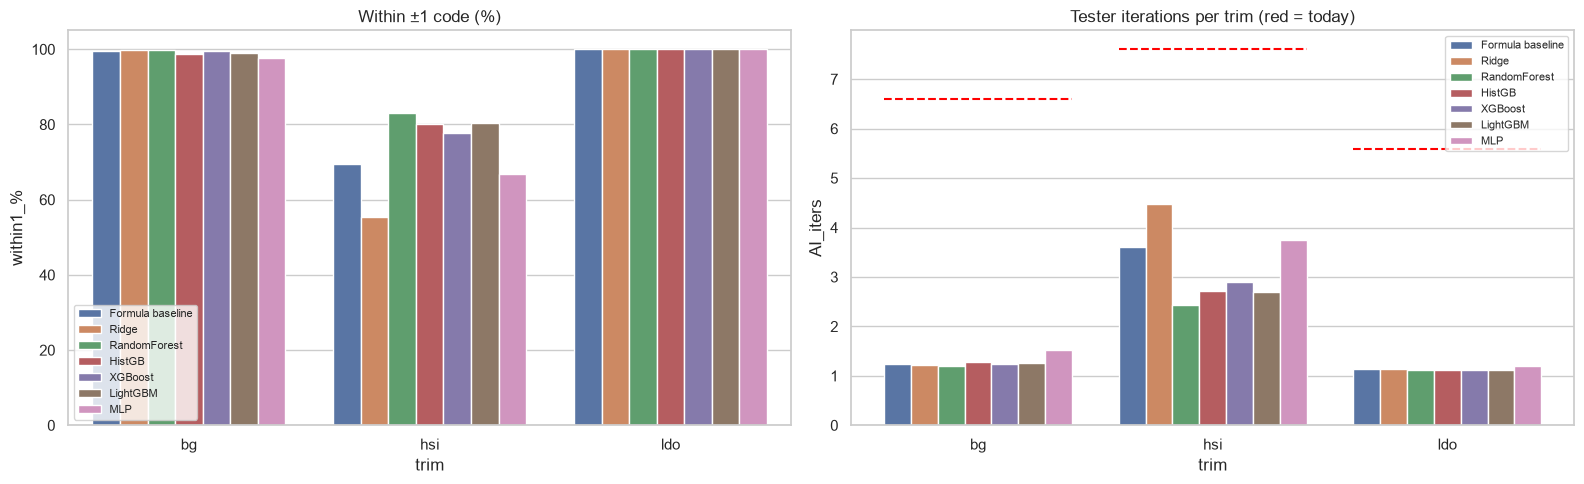

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=res, x="trim", y="within1_%", hue="model", ax=ax[0])
ax[0].set_ylim(0, 105); ax[0].set_title("Within ±1 code (%)"); ax[0].legend(fontsize=8, loc="lower left")
sns.barplot(data=res, x="trim", y="AI_iters", hue="model", ax=ax[1])
for i, t in enumerate(T):
    ax[1].hlines(test[T[t]["conv"]].mean(), i - 0.4, i + 0.4, colors="red", linestyles="--")
ax[1].set_title("Tester iterations per trim (red = today)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Part 5: Deeper evaluation with domain metrics
For each trim we take the best model so far and look closer.

## 5.1 Best model per trim
Ranking rule: highest ±1 code %, then highest exact %, then lowest MAE.

In [25]:
def best_of(frame):
    return frame.sort_values(["within1_%", "exact_%", "MAE"], ascending=[False, False, True]).iloc[0]

best_v1 = {t: best_of(res[res.trim == t]).model for t in T}
print("Best model per trim:", best_v1)

Best model per trim: {'bg': 'Ridge', 'hsi': 'RandomForest', 'ldo': 'RandomForest'}


## 5.2 Error distribution in code steps
How often the best model is exactly right, off by one, or worse. Off by one costs only one extra measurement.

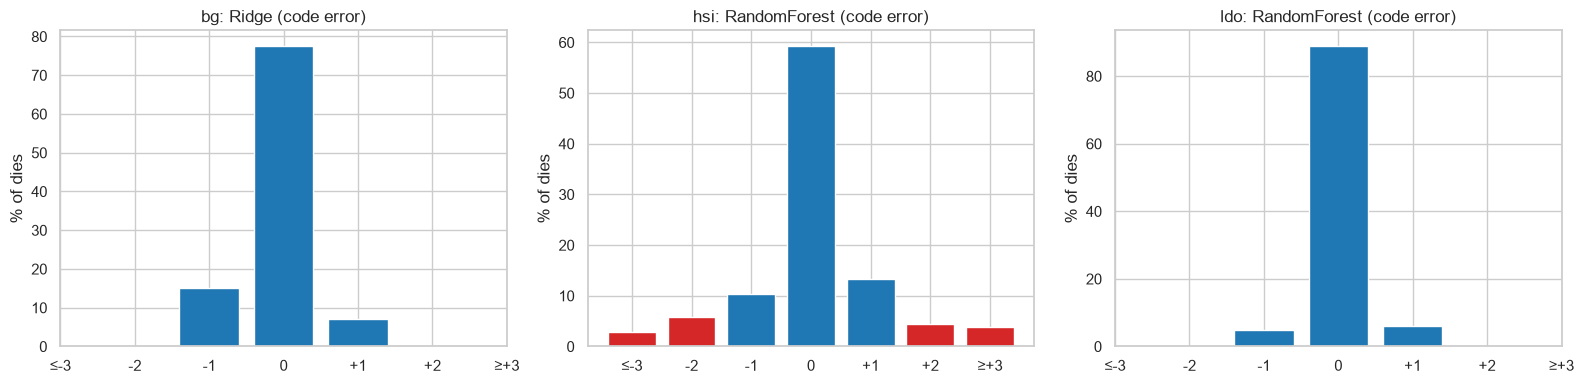

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, t in zip(ax, T):
    m = fitted[(t, best_v1[t])]
    e = to_code(m.predict(test[BASE_FEATS[t]]), t) - test[T[t]["label"]].values
    e = np.clip(e, -3, 3)
    vc = pd.Series(e).value_counts(normalize=True).sort_index() * 100
    a.bar(vc.index, vc.values, color=["#d62728" if abs(i) > 1 else "#1f77b4" for i in vc.index])
    a.set_xticks(range(-3, 4)); a.set_xticklabels(["≤-3", "-2", "-1", "0", "+1", "+2", "≥+3"])
    a.set_title(f"{t}: {best_v1[t]} (code error)"); a.set_ylabel("% of dies")
plt.tight_layout(); plt.show()

## 5.3 Predicted vs. actual code
Points on the red diagonal are perfect predictions.

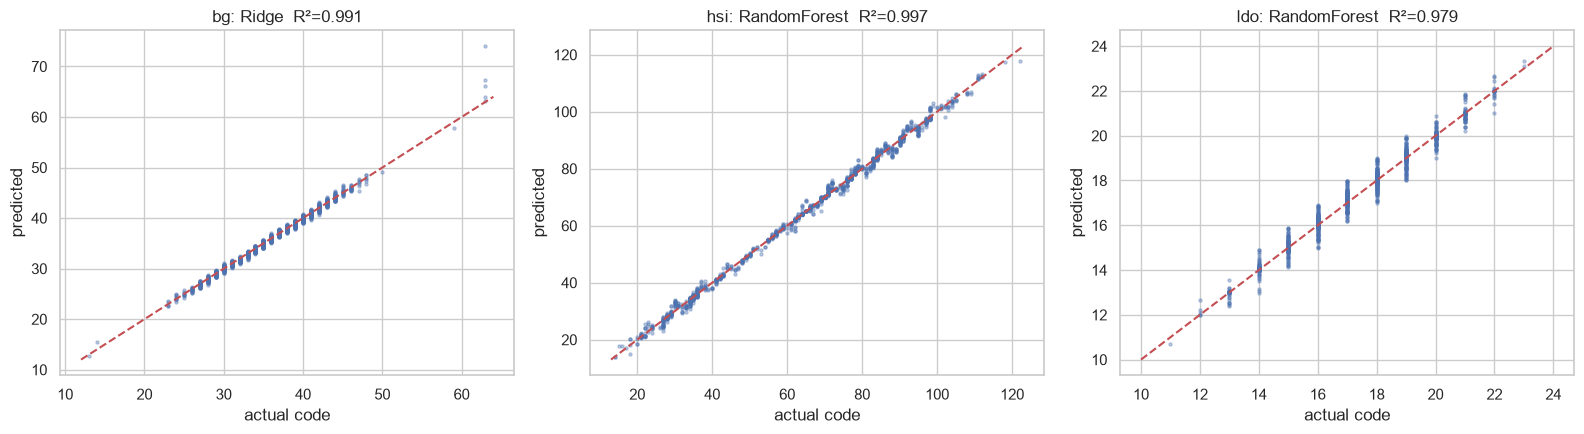

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, t in zip(ax, T):
    y = test[T[t]["label"]]; p = fitted[(t, best_v1[t])].predict(test[BASE_FEATS[t]])
    a.scatter(y, p, s=5, alpha=0.35); lim = [y.min() - 1, y.max() + 1]
    a.plot(lim, lim, "r--"); a.set_xlabel("actual code"); a.set_ylabel("predicted")
    a.set_title(f"{t}: {best_v1[t]}  R²={r2_score(y, p):.3f}")
plt.tight_layout(); plt.show()

## 5.4 Error by wafer zone (centre / middle / edge)
The edge of the wafer is usually harder. This checks whether accuracy drops there.

In [28]:
zone = pd.cut(test.radius_mm, [0, 50, 80, 200], labels=["centre", "middle", "edge"])
rows = []
for t in T:
    m = fitted[(t, best_v1[t])]
    for z in zone.cat.categories:
        part = test[zone == z]
        r = evaluate(t, part, m.predict(part[BASE_FEATS[t]]), best_v1[t]); r["zone"] = z; r["dies"] = len(part)
        rows.append(r)
print(pd.DataFrame(rows)[["trim", "zone", "dies", "exact_%", "within1_%", "AI_iters"]].round(2).to_string(index=False))

trim   zone  dies  exact_%  within1_%  AI_iters
  bg centre   480    77.50     100.00      1.23
  bg middle   784    78.83      99.87      1.22
  bg   edge   416    75.72      99.76      1.25
 hsi centre   480    60.83      83.54      2.38
 hsi middle   784    57.91      81.76      2.52
 hsi   edge   416    60.58      84.38      2.33
 ldo centre   480    90.42     100.00      1.10
 ldo middle   784    88.27     100.00      1.12
 ldo   edge   416    89.18     100.00      1.11


## 5.5 Transfer to the small derivatives (MCU-B, MCU-C)
The model was trained only on MCU-A. Here it is used **as is** (zero-shot) on MCU-B and MCU-C. Trim codes are set at wafer sort, before packaging, so the same IP block should transfer well.

In [29]:
rows = []
for t in T:
    m = fitted[(t, best_v1[t])]
    for d in ["MCU-B", "MCU-C"]:
        part = others[others.derivative == d]
        r = evaluate(t, part, m.predict(part[BASE_FEATS[t]]), best_v1[t]); r["derivative"] = d
        rows.append(r)
print(pd.DataFrame(rows)[["trim", "derivative", "model", "exact_%", "within1_%", "AI_iters", "iters_saved_%"]]
      .round(2).to_string(index=False))

trim derivative        model  exact_%  within1_%  AI_iters  iters_saved_%
  bg      MCU-B        Ridge    63.90     100.00      1.36          79.32
  bg      MCU-C        Ridge    26.72      96.67      1.90          71.17
 hsi      MCU-B RandomForest    59.22      82.34      2.47          67.28
 hsi      MCU-C RandomForest    52.85      78.98      2.73          63.96
 ldo      MCU-B RandomForest    90.34     100.00      1.10          80.46
 ldo      MCU-C RandomForest    83.97     100.00      1.16          79.29


## 5.6 Why the wafer split matters (random vs. grouped)
The same model trained with a *random* die split vs. our *wafer* split. If the random split scores higher, that extra score is optimism that would not hold on a new wafer.

In [30]:
t = "hsi"
rtr, rte = train_test_split(base, test_size=0.25, random_state=SEED)
m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)
r_rand = evaluate(t, rte, m.fit(rtr[BASE_FEATS[t]], rtr[T[t]["label"]]).predict(rte[BASE_FEATS[t]]), "random split")
r_grp = res[(res.trim == t) & (res.model == "HistGB")].iloc[0].to_dict(); r_grp["model"] = "wafer split"
print(pd.DataFrame([r_rand, r_grp])[["model", "MAE", "exact_%", "within1_%"]].round(3).to_string(index=False))

       model   MAE  exact_%  within1_%
random split 0.877   47.435     80.051
 wafer split 0.873   47.387     80.048


## 5.7 Test-time saving for the whole die (all three trims)
Converts iterations into milliseconds using the per-iteration times found in 2.8.

In [31]:
def time_saving(best_map, feats_map, label, data):
    conv_ms = sum(data[T[t]["conv"]].mean() * MS_PER_ITER[t] for t in T)
    ai_ms = sum(evaluate(t, data, fitted_any[(t, best_map[t])].predict(data[feats_map[t]]))["AI_iters"]
                * MS_PER_ITER[t] for t in T)
    print(f"{label}: today {conv_ms:.1f} ms/die -> AI {ai_ms:.1f} ms/die "
          f"(saves {conv_ms - ai_ms:.1f} ms, {100 * (1 - ai_ms / conv_ms):.0f}%)")
    return conv_ms, ai_ms

fitted_any = dict(fitted)
_ = time_saving(best_v1, BASE_FEATS, "Base models", test)

Base models: today 28.7 ms/die -> AI 7.4 ms/die (saves 21.3 ms, 74%)


# Part 6: Can we optimize further?
Two ways to improve, each tested and measured:

1. **Feature engineering:** give the model physics-based features.
   - `ideal_code`: the formula baseline's answer, so the model only needs to learn the *correction*.
   - `err_from_target`: how far the untrimmed value is from its target.
   - For HSI and LDO: the **already-trimmed bandgap** value (`bg_trimmed_sort_V`). On the tester the bandgap is trimmed first, and the HSI oscillator and LDO both run from it, so this value is legitimately known before the HSI and LDO trims. This is the "coupled multi-trim" idea from the brief. It is **not** used for the bandgap model itself, where it would be leakage.
2. **Hyperparameter tuning:** RandomizedSearchCV with **GroupKFold by wafer** on the top two models of each trim.

## 6.1 Feature engineering

In [32]:
def add_features(data):
    d = data.copy()
    for t, c in T.items():
        d[f"{t}_ideal_code"] = formula_code(t, d)
        d[f"{t}_err_from_target"] = d[c["untrim"]] - c["target"]
    return d

train_fe, test_fe, others_fe = add_features(train), add_features(test), add_features(others)
FE_FEATS = {
    "bg":  BASE_FEATS["bg"] + ["bg_ideal_code", "bg_err_from_target"],
    "hsi": BASE_FEATS["hsi"] + ["hsi_ideal_code", "hsi_err_from_target", "bg_trimmed_sort_V"],
    "ldo": BASE_FEATS["ldo"] + ["ldo_ideal_code", "ldo_err_from_target", "bg_trimmed_sort_V"],
}
fe_results = []
for t in T:
    for name, m in make_models().items():
        m.fit(train_fe[FE_FEATS[t]], train_fe[T[t]["label"]])
        fe_results.append(evaluate(t, test_fe, m.predict(test_fe[FE_FEATS[t]]), name))
        fitted_any[(t, name + " +FE")] = m
fe_res = pd.DataFrame(fe_results)

cmp = res[res.model != "Formula baseline"].merge(fe_res, on=["trim", "model"], suffixes=("_base", "_FE"))
print(cmp[["trim", "model", "within1_%_base", "within1_%_FE", "exact_%_base", "exact_%_FE",
           "AI_iters_base", "AI_iters_FE"]].round(2).to_string(index=False))

trim        model  within1_%_base  within1_%_FE  exact_%_base  exact_%_FE  AI_iters_base  AI_iters_FE
  bg        Ridge           99.88         99.88         77.67       77.61           1.23         1.23
  bg RandomForest           99.82         99.88         80.70       80.76           1.20         1.20
  bg       HistGB           98.87         98.57         77.02       76.60           1.29         1.31
  bg      XGBoost           99.52         99.58         79.39       80.94           1.23         1.21
  bg     LightGBM           99.05         99.52         78.62       79.04           1.26         1.23
  bg          MLP           97.80         98.57         59.68       64.19           1.51         1.43
 hsi        Ridge           55.40         71.67         19.89       24.70           4.48         3.45
 hsi RandomForest           82.96         82.78         59.38       59.86           2.43         2.43
 hsi       HistGB           80.05         79.69         47.39       48.16         

## 6.2 Which features help? (ablation for HSI)
Adds the new features one group at a time, to show where the gain comes from. Uses LightGBM (fast).

In [33]:
t = "hsi"; steps = [
    ("base", BASE_FEATS[t]),
    ("+ ideal_code / error", BASE_FEATS[t] + ["hsi_ideal_code", "hsi_err_from_target"]),
    ("+ trimmed bandgap (coupled)", FE_FEATS[t]),
]
rows = []
for label, f in steps:
    m = make_models()["LightGBM"].fit(train_fe[f], train_fe[T[t]["label"]])
    r = evaluate(t, test_fe, m.predict(test_fe[f]), label); rows.append(r)
print(pd.DataFrame(rows)[["model", "MAE", "exact_%", "within1_%", "AI_iters"]].round(3).to_string(index=False))

                      model   MAE  exact_%  within1_%  AI_iters
                       base 0.874   48.931     80.404     2.686
       + ideal_code / error 0.835   50.891     80.879     2.638
+ trimmed bandgap (coupled) 0.827   51.603     80.998     2.624


## 6.3 Hyperparameter tuning (top two models per trim)
Uses RandomizedSearchCV with 4-fold **GroupKFold** on the training wafers (no wafer is ever in both the fit and the check), scored by MAE. The tuned models are then scored on the untouched test wafers.

In [34]:
GRIDS = {
    "Ridge": {"ridge__alpha": np.logspace(-3, 2, 20)},
    "RandomForest": {"n_estimators": [200, 400, 600], "max_depth": [None, 10, 16, 24],
                     "min_samples_leaf": [1, 2, 4, 8], "max_features": [0.5, 0.7, 1.0]},
    "HistGB": {"max_iter": [200, 400, 800], "learning_rate": [0.02, 0.05, 0.08, 0.12],
               "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [10, 20, 40], "l2_regularization": [0, 0.1, 1.0]},
    "XGBoost": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 5, 6, 8],
                "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5]},
    "LightGBM": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [15, 31, 63],
                 "min_child_samples": [10, 20, 40], "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1],
                 "colsample_bytree": [0.6, 0.8, 1.0]},
    "MLP": {"mlpregressor__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32)],
            "mlpregressor__alpha": [1e-4, 1e-3, 1e-2], "mlpregressor__learning_rate_init": [1e-3, 3e-3]},
}
tuned_results = []
for t in T:
    top2 = fe_res[fe_res.trim == t].sort_values(
        ["within1_%", "exact_%", "MAE"], ascending=[False, False, True]).model.head(2).tolist()
    for name in top2:
        search = RandomizedSearchCV(make_models()[name], GRIDS[name], n_iter=12, cv=GroupKFold(n_splits=4),
                                    scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
        search.fit(train_fe[FE_FEATS[t]], train_fe[T[t]["label"]], groups=train_fe.wafer_id)
        r = evaluate(t, test_fe, search.best_estimator_.predict(test_fe[FE_FEATS[t]]), name + " +FE +tuned")
        r["cv_MAE"] = -search.best_score_; r["params"] = search.best_params_
        tuned_results.append(r); fitted_any[(t, name + " +FE +tuned")] = search.best_estimator_
        print(f"{t:4s} {name:12s} cv MAE {-search.best_score_:.3f} | test ±1 {r['within1_%']:.2f}% | "
              f"exact {r['exact_%']:.2f}%")
tuned_res = pd.DataFrame(tuned_results)

bg   RandomForest cv MAE 0.341 | test ±1 99.52% | exact 81.35%


bg   Ridge        cv MAE 0.398 | test ±1 99.88% | exact 77.61%


hsi  RandomForest cv MAE 0.801 | test ±1 83.14% | exact 59.98%


hsi  LightGBM     cv MAE 0.880 | test ±1 81.89% | exact 52.97%


ldo  LightGBM     cv MAE 0.215 | test ±1 100.00% | exact 88.30%


ldo  RandomForest cv MAE 0.176 | test ±1 100.00% | exact 89.19%


## 6.4 Before vs. after optimization
One table per trim: formula, best base model, best with features, and the tuned versions.

In [35]:
fe_tagged = fe_res.assign(model=fe_res.model + " +FE")
everything = pd.concat([res, fe_tagged, tuned_res.drop(columns=["params", "cv_MAE"])], ignore_index=True)
show = ["model", "MAE", "R2", "exact_%", "within1_%", "AI_iters", "iters_saved_%", "spec_pass_%", "edge_code_%"]
for t in T:
    e = everything[everything.trim == t]
    pick = pd.concat([e[e.model == "Formula baseline"], e[e.model == best_v1[t]],
                      e[e.model.str.endswith("+FE")].pipe(lambda x: x.loc[[best_of(x).name]]),
                      e[e.model.str.endswith("+tuned")]])
    print(f"\n===== {t.upper()} =====")
    print(pick[show].round(3).to_string(index=False))


===== BG =====
                  model   MAE    R2  exact_%  within1_%  AI_iters  iters_saved_%  spec_pass_%  edge_code_%
       Formula baseline 0.345 0.989   78.325     99.644     1.235         81.297       99.762        0.297
                  Ridge 0.340 0.991   77.672     99.881     1.229         81.378       99.762        0.297
       RandomForest +FE 0.256 0.994   80.760     99.881     1.198         81.846       99.703        0.059
RandomForest +FE +tuned 0.261 0.994   81.354     99.525     1.210         81.666       99.644        0.000
       Ridge +FE +tuned 0.340 0.991   77.613     99.881     1.230         81.369       99.762        0.297

===== HSI =====
                  model   MAE    R2  exact_%  within1_%  AI_iters  iters_saved_%  spec_pass_%  edge_code_%
       Formula baseline 1.150 0.996   23.990     69.359     3.599         52.686       92.993          0.0
           RandomForest 0.693 0.997   59.382     82.957     2.429         68.067       93.587          0.0
    

# Part 7: Final model selection and saving

## 7.1 Pick the winner for each trim
Among all optimized candidates (`+FE` and `+FE +tuned`), the same ranking rule as before: ±1 code %, then exact %, then MAE. Ties go to the faster, simpler model.

In [36]:
cands = everything[everything.model.str.contains(r"\+FE")]
FINAL = {t: best_of(cands[cands.trim == t]).model for t in T}
final_tbl = pd.concat([cands[(cands.trim == t) & (cands.model == FINAL[t])] for t in T])
print(final_tbl[["trim", "model", "exact_%", "within1_%", "AI_iters", "conv_iters", "iters_saved_%", "spec_pass_%"]]
      .round(2).to_string(index=False))
_ = time_saving(FINAL, FE_FEATS, "Final models", test_fe)

trim                   model  exact_%  within1_%  AI_iters  conv_iters  iters_saved_%  spec_pass_%
  bg        RandomForest +FE    80.76      99.88      1.20        6.60          81.85        99.70
 hsi RandomForest +FE +tuned    59.98      83.14      2.41        7.61          68.29        93.76
 ldo RandomForest +FE +tuned    89.19     100.00      1.11        5.60          80.20       100.00


Final models: today 28.7 ms/die -> AI 7.4 ms/die (saves 21.4 ms, 74%)


## 7.2 Final models on MCU-B and MCU-C (transfer check)

In [37]:
rows = []
for t in T:
    m = fitted_any[(t, FINAL[t])]
    for d in ["MCU-B", "MCU-C"]:
        part = others_fe[others_fe.derivative == d]
        r = evaluate(t, part, m.predict(part[FE_FEATS[t]]), FINAL[t]); r["derivative"] = d; rows.append(r)
print(pd.DataFrame(rows)[["trim", "derivative", "model", "exact_%", "within1_%", "AI_iters"]].round(2).to_string(index=False))

trim derivative                   model  exact_%  within1_%  AI_iters
  bg      MCU-B        RandomForest +FE    80.60      99.92      1.20
  bg      MCU-C        RandomForest +FE    62.23      97.74      1.49
 hsi      MCU-B RandomForest +FE +tuned    59.30      82.42      2.46
 hsi      MCU-C RandomForest +FE +tuned    53.09      79.69      2.69
 ldo      MCU-B RandomForest +FE +tuned    90.42     100.00      1.10
 ldo      MCU-C RandomForest +FE +tuned    84.56     100.00      1.15


## 7.3 Which features does the final bandgap model rely on?
Permutation importance: shuffle one feature and measure how much the error grows. A bigger drop means a more important feature.

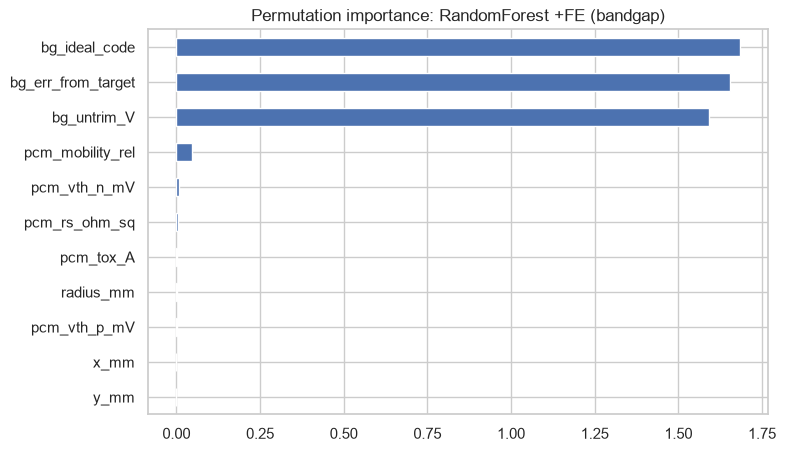

In [38]:
from sklearn.inspection import permutation_importance
t = "bg"; m = fitted_any[(t, FINAL[t])]
pi = permutation_importance(m, test_fe[FE_FEATS[t]], test_fe[T[t]["label"]], n_repeats=5,
                            random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=FE_FEATS[t]).sort_values()
imp.plot.barh(figsize=(8, 5), title=f"Permutation importance: {FINAL[t]} (bandgap)"); plt.show()

## 7.4 Save the final models
One file holds the model, its feature list and the trim settings for each trim. The Streamlit app will load this file later.

In [39]:
bundle = {t: {"model": fitted_any[(t, FINAL[t])], "name": FINAL[t], "features": FE_FEATS[t], "config": T[t]}
          for t in T}
joblib.dump(bundle, "trim_models.joblib")
print("Saved trim_models.joblib (", round(os.path.getsize("trim_models.joblib") / 1e6, 2), "MB )")

Saved trim_models.joblib ( 61.35 MB )


## 7.5 Use the saved models on one die (predict → verify → fallback)
This is how the tester would use the models. Codes at the range edge are sent to the conventional search.

In [40]:
models = joblib.load("trim_models.joblib")

def predict_die(row):
    row = add_features(pd.DataFrame([row]))
    out = {}
    for t, b in models.items():
        code_ = int(to_code(b["model"].predict(row[b["features"]]), t)[0])
        edge = code_ in (0, 2 ** b["config"]["bits"] - 1)
        out[t] = {"predicted_code": code_, "action": "fallback: full search" if edge else "apply + verify"}
    return out

die = test.iloc[0]
print("Die:", die.die_id)
for t, o in predict_die(die).items():
    print(f"  {t:4s} predicted {o['predicted_code']:3d} | true {die[T[t]['label']]:3d} | {o['action']}")

Die: MCU-000000


  bg   predicted  37 | true  37 | apply + verify
  hsi  predicted  35 | true  36 | apply + verify
  ldo  predicted  17 | true  17 | apply + verify


# Part 8: Drift-aware bandgap target (MCU-C)
*(Added after notebook 05 showed this is the one advanced method that helps.)*

After wafer sort the die is packaged, and packaging stress **shifts** the bandgap. A die trimmed perfectly to 1.200 V at sort can land outside the final-test spec (1.200 V ± 5 mV) after packaging. MCU-C (LQFP100, automotive) shifts the most.

**The idea:** predict each die's shift at sort, and trim to an **offset target** (1.200 V − predicted shift), so the die lands on 1.200 V **after** packaging.

## 8.1 How big is the problem today?

In [41]:
df["bg_shift_mV"] = (df.bg_final_V - df.bg_trimmed_sort_V) * 1000
today = df.groupby("derivative").apply(lambda d: pd.Series({
    "mean_shift_mV": d.bg_shift_mV.mean(), "bandgap_final_pass_%": (np.abs(d.bg_final_V - 1.2) <= 5e-3).mean() * 100}))
print(today.round(2).to_string())

            mean_shift_mV  bandgap_final_pass_%
derivative                                     
MCU-A                1.80                 99.65
MCU-B                0.98                 99.92
MCU-C                3.59                 90.74


## 8.2 Predict the shift: zero-shot vs. fine-tuned
MCU-C has only 2 wafers. Training dies come from **wafer 1**; scoring is on **wafer 2**, which is never seen.

| Approach | Training data |
|---|---|
| Zero-shot | MCU-A only (the base product, lots of data) |
| MCU-C only | n MCU-C dies |
| **Fine-tuned** | MCU-A + n MCU-C dies (weighted ×20, plus an MCU-C flag), which is transfer learning |

**Realistic trimming:** the bandgap trim moves in **2 mV steps**, so the offset target is rounded to the nearest step before checking final test.

In [42]:
DRIFT_FEATS = PCM + POS + ["r2"]
df["r2"] = (df.radius_mm / df.radius_mm.max()) ** 2
A_ = df[df.derivative == "MCU-A"]
cw = sorted(df[df.derivative == "MCU-C"].wafer_id.unique())
C1, C2 = df[df.wafer_id == cw[0]], df[df.wafer_id == cw[1]]
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)

def with_offset_target(d, shift_mV):
    # trim to 1.200 V - predicted shift, in 2 mV steps; returns (final V, sort V)
    steps = np.round((1.2 - shift_mV / 1000 - d.bg_trimmed_sort_V) / 0.002)
    sort_v = d.bg_trimmed_sort_V + steps * 0.002
    return d.bg_final_V + (sort_v - d.bg_trimmed_sort_V), sort_v

def fine_tune(tune):
    X = pd.concat([A_[DRIFT_FEATS].assign(is_c=0), tune[DRIFT_FEATS].assign(is_c=1)])
    y = pd.concat([A_.bg_shift_mV, tune.bg_shift_mV])
    w = np.r_[np.ones(len(A_)), np.full(len(tune), 20.0)]
    return hgb().fit(X, y, sample_weight=w)

def row(name, n, pred):
    fin, sort_v = with_offset_target(C2, pred)
    return {"approach": name, "n_MCU-C_dies": n, "shift_MAE_mV": mean_absolute_error(C2.bg_shift_mV, pred),
            "final_pass_%": (np.abs(fin - 1.2) <= 5e-3).mean() * 100}

rows = [{"approach": "Today: trim to 1.200 V", "n_MCU-C_dies": 0, "shift_MAE_mV": np.nan,
         "final_pass_%": (np.abs(C2.bg_final_V - 1.2) <= 5e-3).mean() * 100}]
zero = hgb().fit(A_[DRIFT_FEATS], A_.bg_shift_mV)
rows.append(row("Zero-shot (MCU-A model)", 0, zero.predict(C2[DRIFT_FEATS])))
for n in [10, 25, 50, 100]:
    tune = C1.sample(n, random_state=SEED)
    rows.append(row("MCU-C only (Ridge)", n, make_pipeline(StandardScaler(), Ridge()).fit(
        tune[DRIFT_FEATS], tune.bg_shift_mV).predict(C2[DRIFT_FEATS])))
    rows.append(row("Fine-tuned (MCU-A + MCU-C)", n, fine_tune(tune).predict(C2[DRIFT_FEATS].assign(is_c=1))))
drift = pd.DataFrame(rows)
print(f"MCU-C test wafer {cw[1]}: {len(C2)} dies\n")
print(drift.round(2).to_string(index=False))

MCU-C test wafer MC1-W02: 421 dies

                  approach  n_MCU-C_dies  shift_MAE_mV  final_pass_%
    Today: trim to 1.200 V             0           NaN         90.74
   Zero-shot (MCU-A model)             0          1.62         99.76
        MCU-C only (Ridge)            10          1.24         99.76
Fine-tuned (MCU-A + MCU-C)            10          0.98         99.76
        MCU-C only (Ridge)            25          0.84         99.76
Fine-tuned (MCU-A + MCU-C)            25          0.76         99.76
        MCU-C only (Ridge)            50          1.18         99.52
Fine-tuned (MCU-A + MCU-C)            50          0.90         99.76
        MCU-C only (Ridge)           100          0.83         99.76
Fine-tuned (MCU-A + MCU-C)           100          0.83         99.76


## 8.3 Picture, and a practical note on sort limits
Trimming to an offset target means the die is **deliberately off-centre at sort**. So the sort-test window must be centred on each die's **offset target**, not on 1.200 V. Otherwise good dies would fail sort.

Sort value inside today's window (1.200 V ± 4 mV)      : 59.9%
Sort value inside a window centred on the offset target: 100.0%


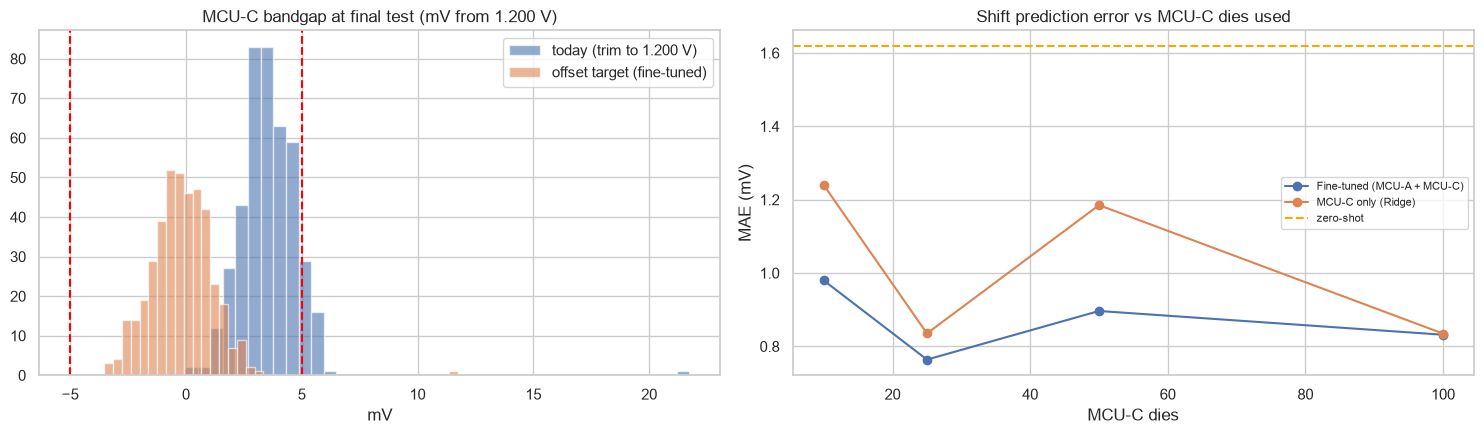

In [43]:
DRIFT_N = 50
drift_model = fine_tune(C1.sample(DRIFT_N, random_state=SEED))
pred = drift_model.predict(C2[DRIFT_FEATS].assign(is_c=1))
fin, sort_v = with_offset_target(C2, pred)
target = 1.2 - pred / 1000
print(f"Sort value inside today's window (1.200 V ± 4 mV)      : {(np.abs(sort_v - 1.2) <= 4e-3).mean():.1%}")
print(f"Sort value inside a window centred on the offset target: {(np.abs(sort_v - target) <= 4e-3).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].hist((C2.bg_final_V - 1.2) * 1000, bins=40, alpha=0.6, label="today (trim to 1.200 V)")
ax[0].hist((fin - 1.2) * 1000, bins=40, alpha=0.6, label="offset target (fine-tuned)")
for x in (-5, 5): ax[0].axvline(x, ls="--", color="red")
ax[0].set(title="MCU-C bandgap at final test (mV from 1.200 V)", xlabel="mV"); ax[0].legend()
g = drift[drift["n_MCU-C_dies"] > 0]
for a_, gg in g.groupby("approach"):
    ax[1].plot(gg["n_MCU-C_dies"], gg.shift_MAE_mV, marker="o", label=a_)
ax[1].axhline(drift[drift.approach.str.startswith("Zero")].shift_MAE_mV.iloc[0], ls="--", color="orange", label="zero-shot")
ax[1].set(title="Shift prediction error vs MCU-C dies used", xlabel="MCU-C dies", ylabel="MAE (mV)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8.4 Add the drift model to the saved bundle
The fine-tuned model with 50 MCU-C dies is kept. Its pass rate equals zero-shot's, but its shift error is about half, which leaves **more margin** if the process drifts.

In [44]:
bundle = joblib.load("trim_models.joblib")
bundle["bg_drift"] = {"model": drift_model, "features": DRIFT_FEATS + ["is_c"], "n_mcu_c_dies": DRIFT_N,
                      "use": "offset target = 1.200 V - predicted shift (mV/1000); r2 = (radius_mm / max radius)^2"}
joblib.dump(bundle, "trim_models.joblib")
print("trim_models.joblib now holds:", list(bundle))

trim_models.joblib now holds: ['bg', 'hsi', 'ldo', 'bg_drift']


# Part 9: Would deep learning, GANs or reinforcement learning help?

**Deep learning (neural networks):** tested above as the **MLP**. On this data it does not beat gradient-boosted trees (see the tables in Part 4 and Part 6). That is expected:
- The data is small and tabular (about 6,000 rows, about 10 features). Trees are usually the strongest choice for this kind of data.
- A tester needs under ~1 ms per prediction, stable behaviour and explainability (automotive ISO 26262). Trees export easily to lookup tables or ONNX.
- **Verdict:** keep the MLP as a comparison. Not worth making it the main model. A CNN on wafer maps could help a future *spatial* model, but there are no images here.

**GAN (generative adversarial network):** generates new fake data.
- Possible use: create extra synthetic dies for MCU-B and MCU-C, which have little data.
- Why not here: the dataset is already synthetic, and the transfer results in 5.5 and 7.2 show the MCU-A model already works on MCU-B and MCU-C. Fake training data also cannot be trusted for one-time-programmable fuses: you cannot verify a GAN's samples against real silicon.
- **Verdict:** not useful for this project.

**RNN / LSTM ("recurrent" models):** built for sequences (time series, text). Each die here is one independent row with no sequence, so there is nothing for them to learn. **Verdict:** not applicable.

**Reinforcement learning (RL):** learns a *sequence of decisions* by trial and reward.
- Possible use: learning the best measurement order across coupled trims, or the search strategy after a missed prediction.
- Why not now: predict-then-verify already needs only 1 to 2 steps, so there is very little left to optimize. RL also needs a simulator or live tester to explore, and is harder to certify.
- **Verdict:** a possible future research item (the brief mentions it for trim *ordering*), not needed for the core model.

**Conclusion:** gradient-boosted trees with physics-based features are the right tool. They are the most accurate here, fast enough for the tester, explainable, and simple to validate.

# Part 10: Why this project, and why this model

## Why I chose the Trim & Fuse project
- **Real, measurable business value:** trimming is a large share of wafer-sort test time on every chip. On this data, predicting the codes cuts trim time from **28.7 ms to about 7.4 ms per die (74 % less)**. On millions of dies, that is a direct tester-cost saving.
- **One method covers the whole chip family:** the same predict-then-verify approach works for MCU, PMIC, sensor and SoC. Models are organised by IP block (bandgap, oscillator, LDO), so a new derivative reuses the base model.
- **Built to fail safe (in simulation):** the model only *proposes* a code. The tester still verifies it with one measurement, and falls back to the normal search when the prediction is off. In the simulation, a wrong prediction costs a few extra milliseconds, not a wrongly blown fuse.
- **A clean, well-documented dataset:** ground-truth optimal codes, conventional iteration counts for savings calculations, and multiple derivatives for transfer testing.

## Why Random Forest is the final model
Six model families were compared on held-out wafers, then improved with physics-based features and tuning.

| Trim | Formula (no ML) ±1 code | Final model | Exact | ±1 code | Tester iterations (today → AI) |
|---|---|---|---|---|---|
| Bandgap | 99.6 % | Random Forest + features | 80.8 % | 99.9 % | 6.6 → 1.20 |
| HSI oscillator | 69.4 % | Random Forest + features + tuned | 60.0 % | 83.1 % | 7.6 → 2.41 |
| LDO | 100 % | Random Forest + features + tuned | 89.2 % | 100 % | 5.6 → 1.11 |

- **Most accurate:** Random Forest ranked first on all three trims. These results beat the dataset's reference baseline (bandgap 97.9 %, HSI 80.4 %, LDO 99.9 % within ±1).
- **Where ML really pays off:** the **HSI oscillator**. The formula gets only 69 % within ±1 code, while Random Forest gets 83 % and saves about 1.2 extra tester iterations per die. For the bandgap and LDO, the formula is already close, and ML mainly adds exact hits.
- **Best transfer to the small derivatives:** on MCU-C (automotive, different package) the bandgap model's exact-hit rate rose from 27 % (Ridge) to 62 % (Random Forest + features), with no MCU-C training data.
- **Robust:** little hyperparameter sensitivity, works without feature scaling, and no extreme codes predicted.
- **Explainable:** permutation importance shows it relies mainly on the untrimmed reading and the physics features, which an engineer can check.

## Drift-aware bandgap target (Part 8)
- Packaging shifts the MCU-C bandgap by about 3.6 mV, so only **90.7%** of MCU-C dies pass final test when trimmed to 1.200 V at sort.
- Trimming to an **offset target** (1.200 V − predicted shift, in real 2 mV steps) raises this to **99.8%** on one unseen MCU-C wafer (99.0–99.8% when each of the two MCU-C wafers is tested in turn, mean 99.4%; see notebook 06).
- **Transfer learning:** fine-tuning the MCU-A drift model with just 50 MCU-C dies cuts the shift-prediction error from 1.62 to 0.90 mV, which leaves more safety margin.
- **Practical requirement:** the sort-test window must be centred on each die's offset target. With today's fixed window, only 60% of MCU-C dies would pass sort.

## Honest findings
- **The MLP neural network was the weakest non-linear model**, which confirms that deep learning is not the right tool for this small tabular dataset (see Part 8).
- **Optimization gave only small gains:** feature engineering helped XGBoost, LightGBM and Ridge on HSI by up to +16 points, but Random Forest improved only slightly after tuning. The base models were already close to the limit of the data.
- **Random vs. wafer split gave the same score here,** because this synthetic data has little wafer-to-wafer variation beyond what the features capture. The wafer split is kept because real fab data does have strong wafer effects.
- **Remaining limit:** the HSI trim stays the hardest (17 % of dies still need the fallback search), because each die's oscillator DAC has its own gain error and non-linearity.
- **The saved Random Forest file is large (about 61 MB).** If needed for deployment, it can be saved compressed (`joblib.dump(..., compress=3)`), or LightGBM can be used instead, which is almost as accurate and much smaller.


## Project summary prompt (copy and paste)
Use this prompt to explain the project, or to give an AI assistant full context for the next step (the Streamlit app, a report, or slides):

```text
I built an AI-Optimized Trim & Fuse project for semiconductor test (MCU derivative chips).

Problem: at wafer sort, each analog block (bandgap 1.200 V, 16 MHz HSI oscillator, 1.10 V LDO)
is trimmed with a binary search of about 6-8 measure/adjust iterations, then the code is burned
into one-time-programmable fuses. This costs about 28.7 ms of tester time per die.

Solution: a machine-learning model predicts each die's optimal trim code from data already
available before trimming (untrimmed reading, 5 process-monitor PCM values, wafer x/y/radius,
plus physics features such as the ideal formula code). The tester applies the predicted code,
verifies it with one measurement, and falls back to the full search only if it is off.

Data: synthetic mcu_trim_fuse.csv, 8,420 dies, 3 derivatives (MCU-A base 6,315 dies;
MCU-B and MCU-C small). Targets: bg_trim_code_opt (6-bit), hsi_trim_code_opt (7-bit),
ldo_trim_code_opt (5-bit). Trained on MCU-A, split by wafer (no wafer in both train and test),
and MCU-B/MCU-C used for the transfer test.

Models compared: formula baseline, Ridge, Random Forest, HistGradientBoosting, XGBoost,
LightGBM, MLP neural network, with feature engineering and RandomizedSearchCV + GroupKFold.

Result: Random Forest is best on all three trims.
- Bandgap: 99.9 % within +/-1 code, 6.6 -> 1.20 iterations
- HSI: 83.1 % within +/-1 code (formula only 69.4 %), 7.6 -> 2.41 iterations
- LDO: 100 % within +/-1 code, 5.6 -> 1.11 iterations
Total trim time drops from 28.7 to about 7.4 ms per die (-74 %). A drift-aware bandgap target (trim to 1.200 V minus the predicted packaging shift, with the
model fine-tuned from MCU-A using 50 MCU-C dies) raises MCU-C final-test pass from 90.7% to
99.8% on one wafer (mean of both MCU-C wafers: 99.4%). The models also transfer to
the MCU-B and MCU-C derivatives without retraining. Deep learning (MLP), GANs, RNNs and
reinforcement learning were evaluated and judged not useful for this small tabular,
verification-critical problem.

Safety (prototype, synthetic data): predictions never blow fuses directly; verify first, fall back on low confidence or
edge codes, and keep security fuses on deterministic rule-based flows.
```
